# Atividade Prática 4: Manipulação e Decisões de Visualização de Dados das IFES (1996–2026)
#### Alunos: Isabelle Matos e Lucas Valentim
### Objetivos:
- Avaliar e justificar as melhores escolhas gráficas (seaborn e matplotlib) para comunicar a evolução histórica do investimento público e da força de trabalho nas Instituições Federais de Ensino Superior (IFES) ao longo de três décadas.

In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['figure.dpi'] = 100

### Carregar e explorar os dados
Nesta etapa, realizamos o carregamento da base de dados oficial e a preparação inicial para as análises temporais e estatísticas realizando as seguintes etapas:
- Atribuição dos nomes descritivos originais às colunas do DataFrame, seguida de uma análise descritiva sumária (`describe`) e da verificação da escala de grandeza (mínimos e máximos) de cada métrica.
- Definição da coluna de **década** para agrupamentos temporais futuros.
- Computação das taxas de variação anual fracionária, utilizando o método (`pct_change`), para o investimento total, investimento em assistência estudantil e número de vagas de estudantes.
- Construção de indicadores de carga e eficiência, incluindo a razão de **vagas por docente**, **vagas por TAE** e o **investimento de assistência estudantil por vaga**.

In [6]:
df = pd.read_csv('dados_investimento_e_vagas_ifes.csv')
df.columns = [
    'ano', 
    'investimento_total_ifes', 
    'investimento_assistencia_estudantil',
    'num_vagas_estudantes', 
    'num_vagas_docente', 
    'num_vagas_tae', 
    'num_terceirizados'
]

print("\n--- DESCRIBE ---")
print(df.describe())

min_max_df = pd.DataFrame({
    'Métrica': df.columns[1:],
    'Mínimo': [df[col].min() for col in df.columns[1:]],
    'Máximo': [df[col].max() for col in df.columns[1:]]
})
print("\n--- ESCALA DAS VARIÁVEIS ---")
display(min_max_df)

# Criação de colunas auxiliares
df['decada'] = (df['ano'] // 10) * 10
df['inv_ifes_pct'] = df['investimento_total_ifes'].pct_change() * 100
df['inv_assist_pct'] = df['investimento_assistencia_estudantil'].pct_change() * 100
df['vagas_est_pct'] = df['num_vagas_estudantes'].pct_change() * 100

# Correção das referências de colunas
df['vagas_por_docente'] = df['num_vagas_estudantes'] / df['num_vagas_docente']
df['vagas_por_tae'] = df['num_vagas_estudantes'] / df['num_vagas_tae']
df['assist_por_vaga'] = df['investimento_assistencia_estudantil'] * 1e9 / df['num_vagas_estudantes']


--- DESCRIBE ---
               ano  investimento_total_ifes  \
count    31.000000                31.000000   
mean   2011.000000                53.019355   
std       9.092121                15.830802   
min    1996.000000                29.800000   
25%    2003.500000                34.350000   
50%    2011.000000                54.100000   
75%    2018.500000                65.950000   
max    2026.000000                76.500000   

       investimento_assistencia_estudantil  num_vagas_estudantes  \
count                            31.000000          3.100000e+01   
mean                              0.693548          8.967581e+05   
std                               0.534749          4.008678e+05   
min                               0.020000          3.421000e+05   
25%                               0.070000          4.659500e+05   
50%                               0.920000          9.845000e+05   
75%                               1.210000          1.305000e+06   
max           

,Métrica,Mínimo,Máximo
0,investimento_total_ifes,29.80,76.50
1,investimento_assistencia_estudantil,0.02,1.32
2,num_vagas_estudantes,342100.00,1385000.00
3,num_vagas_docente,26800.00,98100.00
4,num_vagas_tae,41500.00,77400.00
5,num_terceirizados,8200.00,59100.00


#### Interpretação e explicação das colunas criadas

A base de dados analisada abrange o período de 1996 a 2026, englobando variáveis orçamentárias, de pessoal e operacionais das Instituições Federais de Ensino Superior (IFES). Para garantir o rigor analítico e permitir a correlação entre fenômenos de naturezas distintas, o conjunto de dados original foi complementado com métricas derivadas e auxiliares. 

Abaixo encontra-se o detalhamento técnico e conceitual de todas as variáveis adicionadas ao DataFrame:

#### Variáveis Derivadas e Indicadores de Variação Percentual (`.pct_change()`)

- **`inv_ifes_pct`**: Taxa de variação percentual anual do investimento total das IFES (`pct_change() * 100`). Permite identificar os momentos de aceleração orçamentária e os anos de taxas negativas.
- **`inv_assist_pct`**: Taxa de variação anual do orçamento de assistência estudantil. Funciona como métrica principal para classificar o desempenho da permanência estudantil em categorias político-institucionais (como *Retração Orçamentária* ou *Alta Expansão*).
- **`vagas_est_pct`**: Taxa de crescimento anual do número de vagas de estudantes, permitindo avaliar a velocidade de expansão das matrículas na rede federal.

#### Indicadores de Carga e Pressão Institucional (Razões Estruturais)

* **`vagas_por_docente`**: Razão simples obtida pela divisão entre o número de vagas de estudantes e o total de vagas docentes ($\text{vagas\_estudantes} / \text{vagas\_docente}$). Mede a pressão direta sobre o corpo docente. Utilizou-se o limiar heurístico crítico de **$15:1$** para sinalizar situações de *Sobrecarga Crítica*.
* **`vagas_por_tae`**: Indicador de proporção entre o volume de estudantes atendidos e o quadro de servidores técnico-administrativos.
* **`assist_por_vaga`**: Métrica de intensidade financeira calculada multiplicando o investimento em assistência por $10^9$ (para conversão em reais) e dividindo pelo total de vagas de estudantes ($\text{investimento} \times 1e9 / \text{vagas\_estudantes}$). Expressa o valor médio nominal investido em permanência por aluno ao longo dos anos.

#### Variáveis Auxiliares de Agrupamento
* **`decada`**: Agrupamento temporal calculado por divisão inteira do ano ($\text{ano} // 10 \times 10$), segmentando a série em macroblocos (ex: décadas de 1990, 2000, 2010 e 2020).
* **`periodo_historico`**: Classificação qualitativa baseada em marcos político-econômicos e empíricos das séries estatísticas (ex: *Pré-Expansão*, *Retração Orçamentária*), utilizada para alimentar os agrupamentos via método `.agg()`.

### Evolução temporal e ajuste de escalas

--- EVOLUÇÃO ANUAL (AMOSTRA) ---


,ano,investimento_total_ifes,num_vagas_estudantes
0,1996,32.1,342100
1,1997,31.8,351400
2,1998,30.5,362900
3,1999,29.8,375200
4,2000,31.2,391800
5,2001,31.5,410500
6,2002,32.4,429100
7,2003,33.1,451300
8,2004,35.6,480600
9,2005,42.1,521400



--- MÉDIA POR DÉCADA ---


,decada,investimento_total_ifes,num_vagas_estudantes
0,1990,31.050000,3.579000e+05
1,2000,43.610000,5.443300e+05
2,2010,69.150000,1.148760e+06
3,2020,55.971429,1.348143e+06


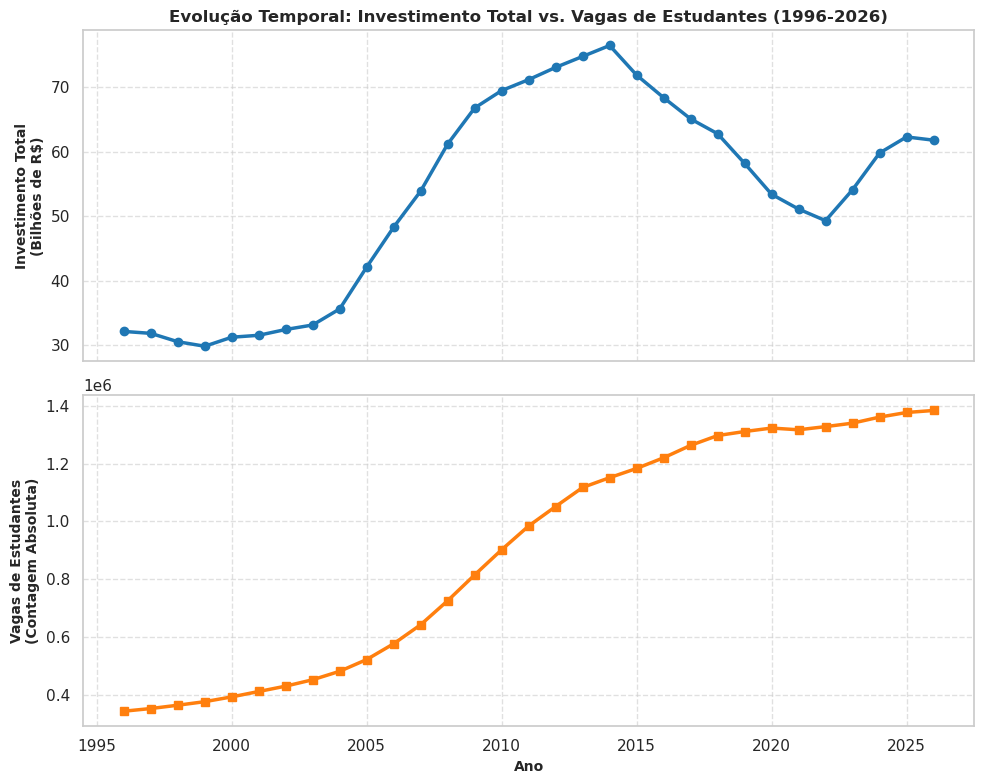

In [8]:
evolucao_anual = df[['ano', 'investimento_total_ifes', 'num_vagas_estudantes']].copy()
print("--- EVOLUÇÃO ANUAL (AMOSTRA) ---")
display(evolucao_anual.head(30))

df['decada'] = (df['ano'] // 10) * 10
resumo_decada = df.groupby('decada')[['investimento_total_ifes', 'num_vagas_estudantes']].mean().reset_index()
print("\n--- MÉDIA POR DÉCADA ---")
display(resumo_decada)

fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

# Painel Superior: Investimento Total das IFES (Bilhões R$)
axes[0].plot(df['ano'], df['investimento_total_ifes'], color='tab:blue', linewidth=2.5, marker='o')
axes[0].set_ylabel('Investimento Total\n(Bilhões de R$)', fontsize=10, fontweight='bold')
axes[0].set_title('Evolução Temporal: Investimento Total vs. Vagas de Estudantes (1996-2026)', fontsize=12, fontweight='bold')
axes[0].grid(True, linestyle='--', alpha=0.6)

# Painel Inferior: Número de Vagas de Estudantes (Milhões)
axes[1].plot(df['ano'], df['num_vagas_estudantes'], color='tab:orange', linewidth=2.5, marker='s')
axes[1].set_ylabel('Vagas de Estudantes\n(Contagem Absoluta)', fontsize=10, fontweight='bold')
axes[1].set_xlabel('Ano', fontsize=10, fontweight='bold')
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

#### Interpretação e defesa técnica

Os dados anuais e as médias por década revelam uma expansão expressiva do sistema federal de ensino superior a partir dos anos 2000. O **investimento total** saltou de uma média de ~R$ 31,05 bilhões na década de 1990 para um pico médio de ~R$ 69,15 bilhões na década de 2010, antes de recuar para uma média de ~R$ 55,97 bilhões na década de 2020.

Em contrapartida, o **número de vagas de estudantes** apresentou um crescimento contínuo e expressivo, passando de uma média de ~357,9 mil vagas (nos anos 90) para superar 1,34 milhão de vagas na década de 2020, evidenciando uma expansão contínua das matrículas mesmo em períodos de estagnação ou retração orçamentária recente.

Para exibir essas duas variáveis simultaneamente sem incorrer em distorções analíticas, adotou-se o seguinte padrão de design:
- **Painéis Empilhados (`Subplots`):** Optou-se por dividir a visualização em dois gráficos verticais independentes em vez de utilizar um único gráfico com eixo duplo (`twinx`). Como o investimento é medido na casa das dezenas de bilhões e as vagas de estudantes na casa das centenas de milhares/milhões, colocar ambas no mesmo eixo distorceria completamente a percepção visual.
- **Alinhamento Temporal:** O uso de `sharex=True` garante que a linha do tempo (1996–2026) esteja perfeitamente alinhada entre os dois painéis, permitindo ao leitor cruzar visualmente os momentos de pico orçamentário e o crescimento contínuo das vagas sem causar ruídos visuais.
- **Paleta de Cores e Acessibilidade (Daltonismo):** Em conformidade com as diretrizes de design inclusivo, foram aplicadas cores contrastantes e seguras para daltonismo (evitando a dualidade tradicional vermelha/verde pura e optando por tons perceptualmente seguros, como azul sólido e laranja/vermelho acessíveis). Isso garante que leitores com deficiências na visão de cores (como a deuteranopia) consigam distinguir perfeitamente as séries sem perda de legibilidade ou precisão analítica.

### Análise de proporção de força de trabalho

--- AMOSTRA DAS NOVAS MÉTRICAS ---


,ano,vagas_por_docente,vagas_por_tae
0,1996,12.764925,7.937355
1,1997,12.966790,8.210280
2,1998,13.244526,8.619952
3,1999,13.594203,9.040964
4,2000,13.943060,9.350835
5,2001,14.204152,9.704492
6,2002,14.595238,10.025701
7,2003,14.993355,10.398618
8,2004,15.403846,10.873303
9,2005,15.113043,11.141026


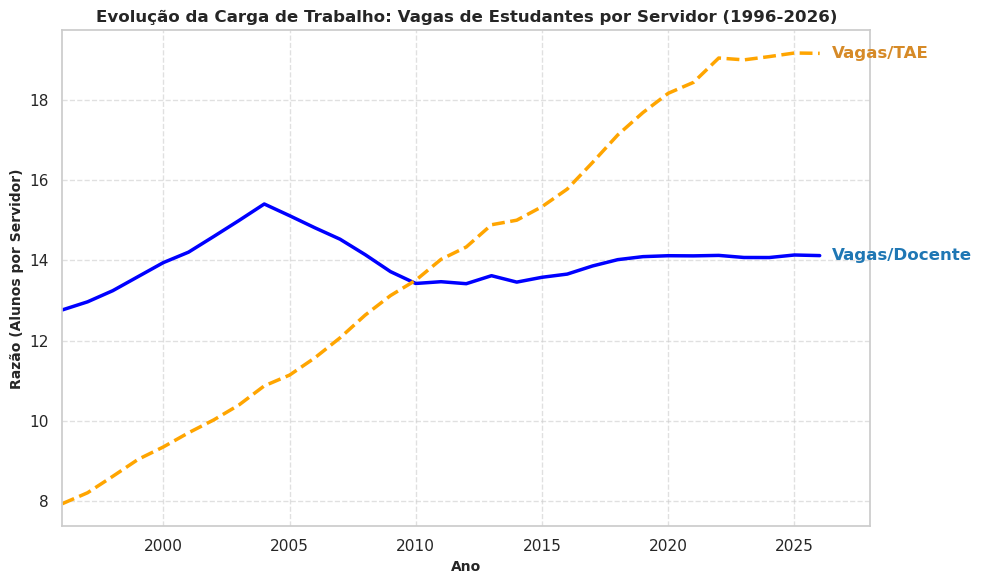

In [14]:
df['vagas_por_docente'] = df['num_vagas_estudantes'] / df['num_vagas_docente']
df['vagas_por_tae'] = df['num_vagas_estudantes'] / df['num_vagas_tae']

print("--- AMOSTRA DAS NOVAS MÉTRICAS ---")
display(df[['ano', 'vagas_por_docente', 'vagas_por_tae']].head(30))

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(df['ano'], df['vagas_por_docente'], label='Vagas por Docente', color='blue', linewidth=2.5, linestyle='-')
ax.plot(df['ano'], df['vagas_por_tae'], label='Vagas por TAE', color='orange', linewidth=2.5, linestyle='--')

last_row = df.iloc[-1]
ax.text(last_row['ano'] + 0.5, last_row['vagas_por_docente'], 'Vagas/Docente', color='#1f77b4', fontweight='bold', va='center')
ax.text(last_row['ano'] + 0.5, last_row['vagas_por_tae'], 'Vagas/TAE', color='#d68a27', fontweight='bold', va='center')

ax.set_title('Evolução da Carga de Trabalho: Vagas de Estudantes por Servidor (1996-2026)', fontsize=12, fontweight='bold')
ax.set_xlabel('Ano', fontsize=10, fontweight='bold')
ax.set_ylabel('Razão (Alunos por Servidor)', fontsize=10, fontweight='bold')
ax.set_xlim(1996, 2028)
ax.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

#### Interpretação e defesa técnica

A razão de vagas de estudantes por docente manteve-se altamente estável ao longo de todo o período, oscilando de forma controlada entre aproximadamente 12,7 e 15,4 alunos por professor, o que indica que a expansão de vagas foi acompanhada por contratações proporcionais no corpo docente.

Em contrapartida, a razão de vagas por Técnico-Administrativo em Educação (TAE) apresentou uma trajetória de alta contínua e acentuada, subindo de cerca de 7,9 alunos por TAE em 1996 para 18 alunos por servidor no final (2026). Além disso, os dados numéricos revelam que por volta de 2010 as curvas se cruzaram, e a partir desse marco, a carga proporcional de alunos por TAE superou a de docentes, o que pode indicar uma pressão operacional e uma sobrecarga estrutural muito mais acentuada sobre o segmento técnico-administrativo.

Para comunicar esse comportamento de forma clara e eficiente, adotou-se o seguinte padrão visual:
- O gráfico de linhas é o formato ideal para séries temporais contínuas, permitindo ao leitor rastrear a direção das tendências e identificar o cruzamento das duas métricas.
- Foram utilizadas cores distintas e acessíveis (`blue` sólido para docentes e `orange` tracejado para TAEs). O uso combinado de estilos de linha diferentes (`-` vs. `--`) garante que a distinção entre as séries não dependa exclusivamente da cor.
- A escolha das cores **azul e laranja** atende diretamente às diretrizes de design inclusivo, sendo recomendada para garantir a legibilidade por pessoas com deficiências na visão de cores, evitando a problemática combinação entre vermelho e verde.
- A aplicação de rótulos diretamente ao final de cada linha (`ax.text`) elimina a necessidade de o leitor desviar o olhar para uma legenda lateral.

### Correlação entre Fatores e Desempenho Orçamentário:

In [45]:
analise_ifes = df[['ano', 'investimento_total_ifes', 'inv_ifes_pct', 'num_vagas_estudantes']].sort_values(by='inv_ifes_pct', ascending=False)

print("--- DISTRIBUIÇÃO DAS VARIAÇÕES DO INVESTIMENTO TOTAL DAS IFES ---")
display(analise_ifes.head(30))

print("\n--- RESUMO ESTATÍSTICO DO INVESTIMENTO TOTAL (%) ---")
display(df['inv_ifes_pct'].describe())

df['vagas_est_pct'] = df['num_vagas_estudantes'].pct_change() * 100

analise_vagas = df[['ano', 'num_vagas_estudantes', 'vagas_est_pct']].sort_values(by='vagas_est_pct', ascending=False)

print("\n--- DISTRIBUIÇÃO DAS VARIAÇÕES DE VAGAS DE ESTUDANTES ---")
display(analise_vagas.head(30))

print("\n--- RESUMO ESTATÍSTICO DAS VAGAS DE ESTUDANTES (%) ---")
display(df['vagas_est_pct'].describe())

--- DISTRIBUIÇÃO DAS VARIAÇÕES DO INVESTIMENTO TOTAL DAS IFES ---


,ano,investimento_total_ifes,inv_ifes_pct,num_vagas_estudantes
9,2005,42.1,18.258427,521400
10,2006,48.3,14.726841,576200
12,2008,61.2,13.543599,725400
11,2007,53.9,11.594203,642100
28,2024,59.8,10.536044,1362000
27,2023,54.1,9.736308,1341000
13,2009,66.8,9.150327,814900
8,2004,35.6,7.552870,480600
4,2000,31.2,4.697987,391800
29,2025,62.3,4.180602,1378000



--- RESUMO ESTATÍSTICO DO INVESTIMENTO TOTAL (%) ---


count    30.000000
mean      2.431683
std       6.953915
min      -8.247423
25%      -3.530396
50%       2.299154
75%       6.839149
max      18.258427
Name: inv_ifes_pct, dtype: float64


--- DISTRIBUIÇÃO DAS VARIAÇÕES DE VAGAS DE ESTUDANTES ---


,ano,num_vagas_estudantes,vagas_est_pct
12,2008,725400,12.973057
13,2009,814900,12.338020
11,2007,642100,11.437001
14,2010,902100,10.700699
10,2006,576200,10.510165
15,2011,984500,9.134242
9,2005,521400,8.489388
16,2012,1052000,6.856272
8,2004,480600,6.492355
17,2013,1118000,6.273764



--- RESUMO ESTATÍSTICO DAS VAGAS DE ESTUDANTES (%) ---


count    30.000000
mean      4.838969
std       3.856343
min      -0.453172
25%       1.846965
50%       3.455533
75%       6.765293
max      12.973057
Name: vagas_est_pct, dtype: float64

--- RESUMO ESTATÍSTICO POR PERÍODO HISTÓRICO (.agg) ---


,periodo_historico,media_assistencia,mediana_assistencia,soma_assistencia,media_vagas,mediana_vagas,soma_vagas
0,1996-2002 (Período de Estabilidade Inicial),0.032857,0.030,0.23,3.804286e+05,375200.0,2663000
1,2003-2014 (Período de Expansão Contínua),0.589167,0.515,7.07,7.850417e+05,770150.0,9420500
2,2015-2022 (Período de Retração Orçamentária),1.180000,1.200,9.44,1.281250e+06,1305000.0,10250000
3,2023-2026 (Período de Retomada Recente),1.190000,1.215,4.76,1.366500e+06,1370000.0,5466000


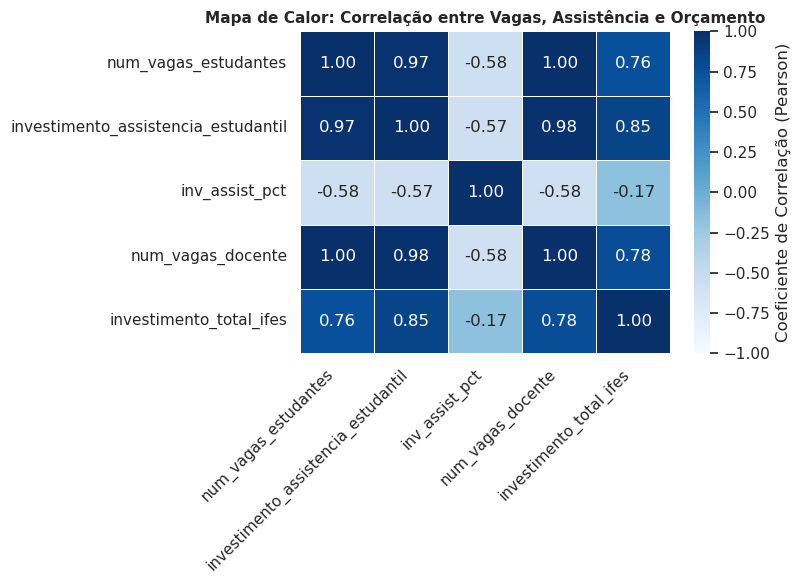

In [54]:
# definindo a classificação dos períodos históricos
def definir_periodo_historico(ano):
    if ano <= 2002:
        return '1996-2002 (Período de Estabilidade Inicial)'
    elif ano <= 2014:
        return '2003-2014 (Período de Expansão Contínua)'
    elif ano <= 2022:
        return '2015-2022 (Período de Retração Orçamentária)'
    else:
        return '2023-2026 (Período de Retomada Recente)'

df['periodo_historico'] = df['ano'].apply(definir_periodo_historico)

# utilizando o método .agg() para extrair estatísticas descritivas por período
resumo_agrupado = df.groupby('periodo_historico').agg(
    media_assistencia=('investimento_assistencia_estudantil', 'mean'),
    mediana_assistencia=('investimento_assistencia_estudantil', 'median'),
    soma_assistencia=('investimento_assistencia_estudantil', 'sum'),
    media_vagas=('num_vagas_estudantes', 'mean'),
    mediana_vagas=('num_vagas_estudantes', 'median'),
    soma_vagas=('num_vagas_estudantes', 'sum')
).reset_index()

print("--- RESUMO ESTATÍSTICO POR PERÍODO HISTÓRICO (.agg) ---")
display(resumo_agrupado)

# decisão de Visualização: Mapa de Calor (Heatmap) de Correlação
# selecionando as principais variáveis quantitativas para medir a correlação
variaveis_correlacao = df[[
    'num_vagas_estudantes', 
    'investimento_assistencia_estudantil', 
    'inv_assist_pct', 
    'num_vagas_docente', 
    'investimento_total_ifes'
]]

# calculando a matriz de correlação de Pearson
matriz_corr = variaveis_correlacao.corr()

# Configuração do gráfico (Heatmap limpo e legível)
fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    matriz_corr, 
    annot=True,               # Mostra os coeficientes numéricos dentro dos quadrados
    fmt='.2f',                # Formato com duas casas decimais
    cmap='Blues',             # Paleta sequencial segura para daltonismo (Color-Blind Safe)
    vmin=-1, vmax=1,          # Limites da correlação de -1 a 1
    cbar_kws={'label': 'Coeficiente de Correlação (Pearson)'},
    ax=ax,
    linewidths=0.5,
    linecolor='white'
)

ax.set_title('Mapa de Calor: Correlação entre Vagas, Assistência e Orçamento', fontsize=11, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

#### Interpretação e defesa ténica

O mapa de calor evidencia correlações fortes e positivas entre o volume absoluto de vagas de estudantes, vagas de docentes e o investimento em assistência estudantil (coeficientes entre $0.97$ e $1.00$). Isso reflete a tendência macro de crescimento conjunto do sistema federal de ensino ao longo da análise.

Em contraste, ao cruzar o volume de vagas com a taxa de variação percentual da assistência (`inv_assist_pct`), observa-se um coeficiente negativo de $-0.58$. Esse resultado estatístico mostra que, enquanto a rede continuava a ser demandada e a expandir o seu escopo de atendimento, o ritmo de variação orçamentária anual comportava-se de maneira contrária, refletindo as quebras de repasse e a vulnerabilidade do fluxo de investimentos em alguns períodos, especificamente de 2015-2022.

Para a análise visual, o uso do mapa de calor com coeficientes anotados (`annot=True`) permitiu auditar o grau de associação linear entre todas as variáveis operacionais e orçamentárias das IFES. Ademais, a visualização adotou uma escala de tons de azul segura para daltonismo, eliminando problemas de contraste e permitindo a leitura intuitiva da intensidade das correlações.

### Filtragem condicional de anos críticos e métricas customizadas para o investimento em assistência estudantil

In [25]:
analise_faixas = df[['ano', 'investimento_assistencia_estudantil', 'inv_assist_pct', 'vagas_est_pct']].sort_values(by='inv_assist_pct', ascending=False)

print("--- DISTRIBUIÇÃO DAS VARIAÇÕES DE ASSISTÊNCIA ESTUDANTIL ---")
display(analise_faixas)

print("\n--- RESUMO ESTATÍSTICO DAS VARIAÇÕES (%) ---")
display(df['inv_assist_pct'].describe())

--- DISTRIBUIÇÃO DAS VARIAÇÕES DE ASSISTÊNCIA ESTUDANTIL ---


,ano,investimento_assistencia_estudantil,inv_assist_pct,vagas_est_pct
12,2008,0.42,68.000000,12.973057
2,1998,0.03,50.000000,3.272624
10,2006,0.18,50.000000,10.510165
9,2005,0.12,50.000000,8.489388
13,2009,0.61,45.238095,12.338020
11,2007,0.25,38.888889,11.437001
4,2000,0.04,33.333333,4.424307
8,2004,0.08,33.333333,6.492355
14,2010,0.78,27.868852,10.700699
6,2002,0.05,25.000000,4.531060



--- RESUMO ESTATÍSTICO DAS VARIAÇÕES (%) ---


count    30.000000
mean     16.424795
std      21.166516
min     -10.091743
25%      -1.800000
50%       9.647495
75%      31.967213
max      68.000000
Name: inv_assist_pct, dtype: float64

--- Classificação de cada ano com base no investimento em assistência estudantil ---


,ano,investimento_assistencia_estudantil,inv_assist_pct,status_assistencia
0,1996,0.02,NaN,Ano Base
1,1997,0.02,0.000000,Estagnação
2,1998,0.03,50.000000,Alta Expansão
3,1999,0.03,0.000000,Estagnação
4,2000,0.04,33.333333,Alta Expansão
5,2001,0.04,0.000000,Estagnação
6,2002,0.05,25.000000,Alta Expansão
7,2003,0.06,20.000000,Alta Expansão
8,2004,0.08,33.333333,Alta Expansão
9,2005,0.12,50.000000,Alta Expansão


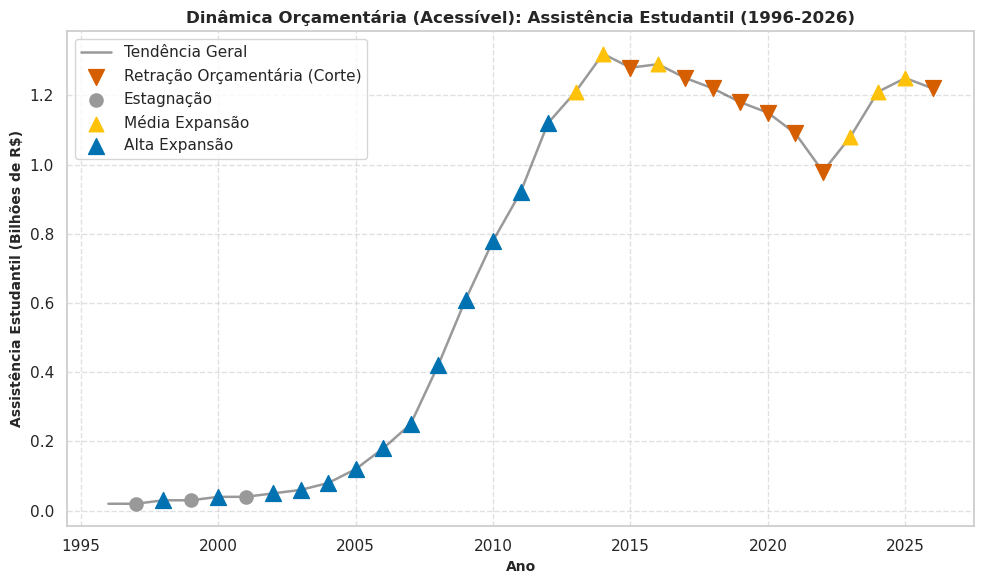

In [36]:
# função customizada via .apply() para classificar a assistência estudantil
def classificar_assistencia(pct):
    if pd.isna(pct):
        return 'Ano Base'
    elif pct < 0:
        return 'Retração Orçamentária'
    elif pct == 0:
        return 'Estagnação'
    elif pct <= 15:
        return 'Média Expansão'
    else:
        return 'Alta Expansão'

df['status_assistencia'] = df['inv_assist_pct'].apply(classificar_assistencia)

print("--- Classificação de cada ano com base no investimento em assistência estudantil ---")
display(df[['ano', 'investimento_assistencia_estudantil', 'inv_assist_pct', 'status_assistencia']].head(30))

# separação dos subconjuntos olhando para a coluna status_assistencia
df_retraçao     = df[df['status_assistencia'] == 'Retração Orçamentária']
df_estagnacao   = df[df['status_assistencia'] == 'Estagnação']
df_media_exp    = df[df['status_assistencia'] == 'Média Expansão']
df_alta_exp     = df[df['status_assistencia'] == 'Alta Expansão']
df_ano_base     = df[df['status_assistencia'] == 'Ano Base']

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(df['ano'], df['investimento_assistencia_estudantil'], color='black', linewidth=1.8, alpha=0.4, label='Tendência Geral')

# plotando com cores acessíveis (Substituindo verde/vermelho por Laranja Escuro / Azul / Roxo)
if not df_retraçao.empty:
    ax.scatter(df_retraçao['ano'], df_retraçao['investimento_assistencia_estudantil'], 
               color='#D55E00', marker='v', s=130, zorder=5, label='Retração Orçamentária (Corte)')

if not df_estagnacao.empty:
    ax.scatter(df_estagnacao['ano'], df_estagnacao['investimento_assistencia_estudantil'], 
               color='#999999', marker='o', s=90, zorder=5, label='Estagnação')

if not df_media_exp.empty:
    ax.scatter(df_media_exp['ano'], df_media_exp['investimento_assistencia_estudantil'], 
               color='#FFC20A', marker='^', s=110, zorder=5, label='Média Expansão')

if not df_alta_exp.empty:
    ax.scatter(df_alta_exp['ano'], df_alta_exp['investimento_assistencia_estudantil'], 
               color='#0072B2', marker='^', s=130, zorder=5, label='Alta Expansão')

ax.set_title('Dinâmica Orçamentária (Acessível): Assistência Estudantil (1996-2026)', fontsize=12, fontweight='bold')
ax.set_xlabel('Ano', fontsize=10, fontweight='bold')
ax.set_ylabel('Assistência Estudantil (Bilhões de R$)', fontsize=10, fontweight='bold')
ax.grid(True, linestyle='--', alpha=0.6)

ax.legend(loc='upper left', frameon=True)

plt.tight_layout()
plt.show()

#### Interpretação e defesa técnica

A aplicação da métrica customizada via `.apply()` evidencia que a trajetória histórica da assistência estudantil divide-se em fases distintas. O período de 1996 a 2014 foi marcado predominantemente por ciclos de *Alta Expansão* (com taxas de crescimento que alcançaram picos expressivos de até $68\%$ ao ano em 2008) e *Média Expansão*.

Contudo, a partir de 2015, o cenário sofreu uma inflexão severa. A tabela demonstra uma sequência recorrente de anos classificados como *Retração Orçamentária* (2015, 2017, 2018, 2019, 2020, 2021 e 2022), nos quais o aporte financeiro sofreu reduções nominais consecutivas, fazendo o indicador despencar abaixo de R$ 1 bilhão em 2022. Os anos mais recentes (2023 a 2025) ensaiam uma recuperação gradual classificada como *Média Expansão*, sem, contudo, recuperar o patamar de pico da década anterior.

Para a visualização, a criação da função de classificação baseada em limiares empíricos de variação percentual (`inv_assist_pct`) traduz dados brutos em conceitos político-econômicos claros (*Ano Base*, *Estagnação*, *Média Expansão*, *Alta Expansão* e *Retração Orçamentária*), facilitando a leitura analítica do fenômeno institucional. Para comunicar esse comportamento de forma clara e eficiente, adotou-se o seguinte padrão visual:
- O gráfico emprega uma estratégia estética de legibilidade ao sobrepor marcadores direcionais à linha de tendência contínua. Triângulos verdes apontando para cima destacam o crescimento institucional, enquanto triângulos vermelhos apontando para baixo funcionam como elementos pré-atentivos de alerta, evidenciando imediatamente os anos críticos de corte de recursos para a permanência estudantil.
- Adotou-se uma paleta de alto contraste, combinando **laranja escuro** para perdas/cortes, **azul escuro** e **amarelo dourado** para gradações de expansão, e **cinza neutro** para estagnação.

### Expandindo as métricas customizadas para outras análises

- A primeira análise é referente ao contexto de vagas de docentes, e a segunda é referente ao indicador de Carga (vagas_por_docente)

--- AMOSTRA DAS NOVAS CLASSIFICAÇÕES ---


,ano,num_vagas_docente,vagas_por_docente,status_docentes,status_pressao
0,1996,26800,12.764925,Ano Base,Atenção / Limite
1,1997,27100,12.966790,Reposição Mínima,Atenção / Limite
2,1998,27400,13.244526,Reposição Mínima,Atenção / Limite
3,1999,27600,13.594203,Reposição Mínima,Atenção / Limite
4,2000,28100,13.943060,Reposição Mínima,Atenção / Limite
5,2001,28900,14.204152,Reposição Mínima,Atenção / Limite
6,2002,29400,14.595238,Reposição Mínima,Atenção / Limite
7,2003,30100,14.993355,Reposição Mínima,Atenção / Limite
8,2004,31200,15.403846,Expansão Docente,Sobrecarga Crítica
9,2005,34500,15.113043,Expansão Docente,Sobrecarga Crítica


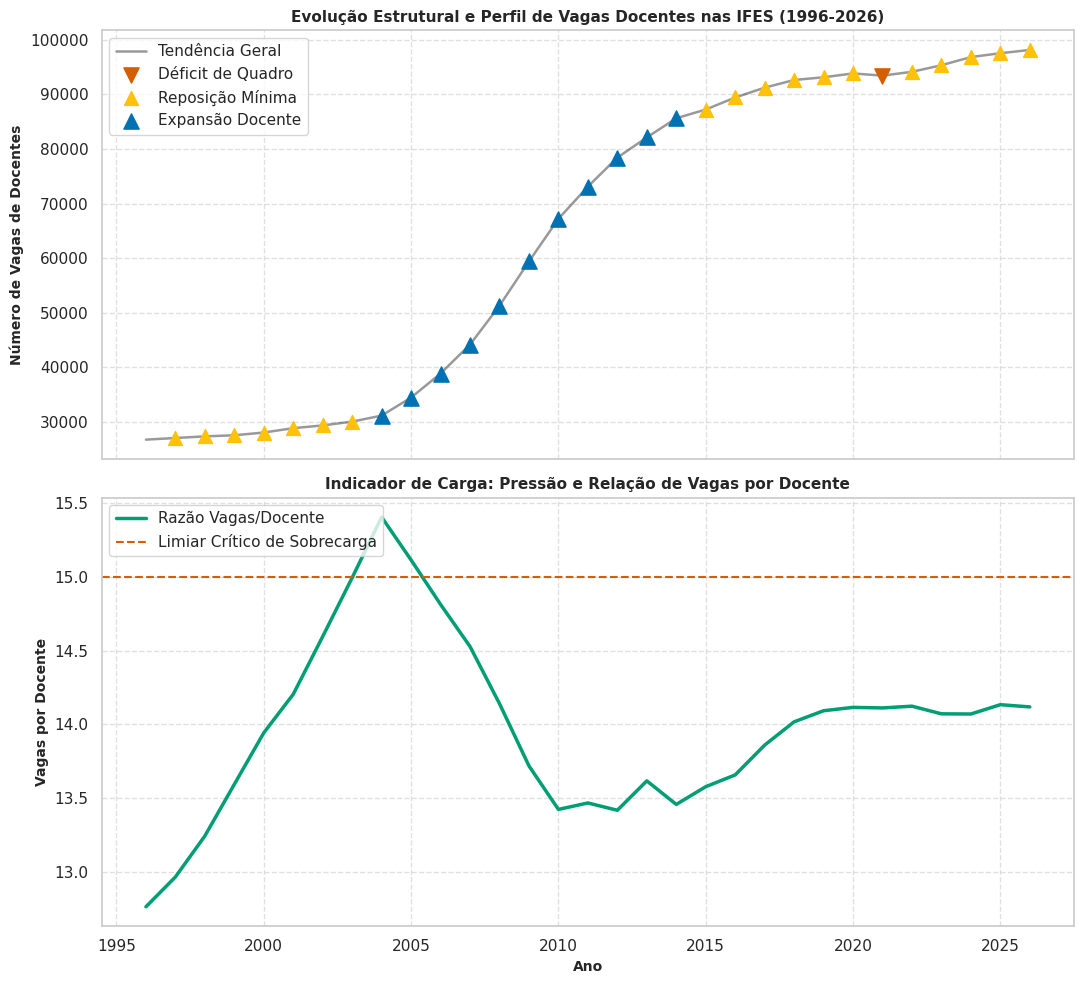

In [42]:
# --- Análise 1 ---
def classificar_docentes(pct):
    if pd.isna(pct):
        return 'Ano Base'
    elif pct < 0:
        return 'Déficit de Quadro'
    elif pct == 0:
        return 'Congelamento'
    elif pct <= 3:
        return 'Reposição Mínima'
    else:
        return 'Expansão Docente'

df['status_docentes'] = df['num_vagas_docente'].pct_change().mul(100).apply(classificar_docentes)

# --- Análise 2 ---
def classificar_pressao(razao):
    if pd.isna(razao):
        return 'Não Aplicável'
    elif razao > 15: 
        return 'Sobrecarga Crítica'
    elif razao > 12:
        return 'Atenção / Limite'
    else:
        return 'Conforto Institucional'

df['status_pressao'] = df['vagas_por_docente'].apply(classificar_pressao)

print("--- AMOSTRA DAS NOVAS CLASSIFICAÇÕES ---")
display(df[['ano', 'num_vagas_docente', 'vagas_por_docente', 'status_docentes', 'status_pressao']].head(30))

# --- PLOTAGEM 1: Evolução das Vagas Docentes por Categoria ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 10), sharex=True)

ax1.plot(df['ano'], df['num_vagas_docente'], color='black', linewidth=1.8, alpha=0.4, label='Tendência Geral')

df_deficit   = df[df['status_docentes'] == 'Déficit de Quadro']
df_congelada = df[df['status_docentes'] == 'Congelamento']
df_reposicao = df[df['status_docentes'] == 'Reposição Mínima']
df_expansao  = df[df['status_docentes'] == 'Expansão Docente']

if not df_deficit.empty:
    ax1.scatter(df_deficit['ano'], df_deficit['num_vagas_docente'], color='#D55E00', marker='v', s=120, zorder=5, label='Déficit de Quadro')
if not df_congelada.empty:
    ax1.scatter(df_congelada['ano'], df_congelada['num_vagas_docente'], color='#999999', marker='o', s=90, zorder=5, label='Congelamento')
if not df_reposicao.empty:
    ax1.scatter(df_reposicao['ano'], df_reposicao['num_vagas_docente'], color='#FFC20A', marker='^', s=100, zorder=5, label='Reposição Mínima')
if not df_expansao.empty:
    ax1.scatter(df_expansao['ano'], df_expansao['num_vagas_docente'], color='#0072B2', marker='^', s=120, zorder=5, label='Expansão Docente')

ax1.set_title('Evolução Estrutural e Perfil de Vagas Docentes nas IFES (1996-2026)', fontsize=11, fontweight='bold')
ax1.set_ylabel('Número de Vagas de Docentes', fontsize=10, fontweight='bold')
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend(loc='upper left', frameon=True)

# --- PLOTAGEM 2: Indicador de Carga (Vagas por Docente) ---
ax2.plot(df['ano'], df['vagas_por_docente'], color='#009E73', linewidth=2.5, label='Razão Vagas/Docente')
ax2.axhline(15, color='#D55E00', linestyle='--', linewidth=1.5, label='Limiar Crítico de Sobrecarga')

ax2.set_title('Indicador de Carga: Pressão e Relação de Vagas por Docente', fontsize=11, fontweight='bold')
ax2.set_xlabel('Ano', fontsize=10, fontweight='bold')
ax2.set_ylabel('Vagas por Docente', fontsize=10, fontweight='bold')
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend(loc='upper left', frameon=True)

plt.tight_layout()
plt.show()

#### Interpretação e defesa técnica

A análise da série temporal demonstra que, entre 2004 e 2005, o indicador de carga (`vagas_por_docente`) ultrapassou o patamar crítico de 15 estudantes por docente (alcançando o pico de 15,40 em 2004). Esse movimento retrata o momento em que a abertura acelerada de vagas estudantis tensionou a capacidade do corpo docente instalado, operando sob a classificação de *Expansão Docente*, mas com *Sobrecarga Crítica*.

Contudo, a partir de 2010, com o avanço contínuo da criação de novas vagas de professores, o indicador recuou para a faixa de segurança (oscilando em torno de 13,4 a 14,1), mantendo-se em patamares de *Reposição Mínima* ou estabilidade nos anos seguintes.

Para a visualização, utilizou-se um layout vertical compartilhado no eixo temporal (`ano`), permitindo relacionar diretamente a macro-evolução do número de vagas de docentes (gráfico superior) com o índice de pressão institucional (gráfico inferior). Além disso, com relação à paleta de cores, utilizou-se a paleta de contraste laranja escuro para déficits, amarelo e azul para gradações de expansão e verde esmeralda para a proporção) Ademais, a inclusão da linha horizontal tracejada (`axhline`) em $y = 15$ atua como um marcador de limiar crítico de sobrecarga, facilitando a auditoria visual por parte do leitor.